# Exploration de la table de modélisation
**Contributeur :** Théophyle CHEVET · **Date :** 02/11/2026

Table `table_modelisation_bv.parquet` : une ligne par sous-bassin × année × type de bien (prix N et prix N-1 calculés sur au moins 20 ventes).

**But :** vérifier la table, comprendre la cible, choisir les variables et leur transformation, puis résumer les variables du territoire par une ACP. Les statistiques portent sur les années d'apprentissage (2020-2023) ; 2024 et 2025 ne sont pas regardées.

In [16]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sys.path.insert(0, str(Path.cwd().parent))
from config import DATA_OUT

ANNEE_DEBUT = 2020          # première année d'apprentissage (comme commun.py)
ANNEE_VALIDATION = 2024     # année de validation (comme commun.py)

table = pd.read_parquet(DATA_OUT / "table_modelisation_bv.parquet")
table = table.reset_index(level=["sous_bassin_de_vie", "type_bien"])   # clés remises en colonnes
table.index = range(len(table))
apprentissage = table[(table["annee"] >= ANNEE_DEBUT) & (table["annee"] < ANNEE_VALIDATION)]

## 1. Contrôle de la table
On vérifie le nombre de lignes par année et par type de bien, l'absence de doublons et l'origine des valeurs vides.

In [17]:
print(table.shape, "| sous-bassins :", table["sous_bassin_de_vie"].nunique(),
      "| doublons :", table.duplicated(["annee", "sous_bassin_de_vie", "type_bien"]).sum())
display(table.groupby(["annee", "type_bien"]).size().unstack())

# Valeurs vides : nombre de lignes par variable
vides = table.isna().sum()
print(vides[vides > 0].to_string())

# Délinquance vide : quelles années ?
print("Délinquance vide par année :", table["taux3_cambriolages"].isna().groupby(table["annee"]).sum().to_dict())
print("Sous-bassin sans LOVAC :", table.loc[table["taux_vacance_complete"].isna(), "sous_bassin_de_vie"].unique())

(28450, 40) | sous-bassins : 1811 | doublons : 0


type_bien,appartement,maison
annee,,
2015,691,1769
2016,717,1775
2017,746,1776
2018,774,1780
2019,805,1780
2020,857,1780
2021,878,1781
2022,912,1782
2023,861,1781


part_indicateurs_estimes           4952
taux3_vols_vehicules               4952
taux3_vols_violents                4952
taux3_vols_sans_violence           4952
taux3_cambriolages                 4952
taux3_destructions                 4952
taux3_stupefiants                  4952
taux3_violences_intrafamiliales    4952
taux3_violences_sexuelles          4952
taux_vacance_complete                11
part_logements_taux_impute           11
Délinquance vide par année : {2015: 2460, 2016: 2492, 2017: 0, 2018: 0, 2019: 0, 2020: 0, 2021: 0, 2022: 0, 2023: 0, 2024: 0, 2025: 0}
Sous-bassin sans LOVAC : <ArrowStringArray>
['49069']
Length: 1, dtype: str


**Résultat :**
- 28 450 lignes, 1 811 sous-bassins, **aucun doublon**.
- Environ 1 780 sous-bassins par an pour les **maisons**, mais 690 à 910 pour les **appartements** : beaucoup de territoires ruraux n'ont pas 20 ventes d'appartements par an.
- **Valeurs vides :**
  - délinquance, pour les prix **2015 et 2016** seulement (4 952 lignes) : les faits commencent en 2016 et servent l'année suivante ;
  - LOVAC, pour **un seul sous-bassin** (49069, 11 lignes).

**Conclusion :** sur les années de modélisation (2020-2025), seules les 11 lignes du sous-bassin 49069 sont incomplètes. Il faudra les retirer pour la régression linéaire.

## 2. La cible
On regarde la forme du prix au m² et son lien avec le prix de l'année précédente, qui sert de référence (prévision naïve).

maison : médiane = 1841.5 €/m² | asymétrie = 3.25 | en log : 0.33 | rho avec le prix N-1 = 0.988
   évolution médiane N-1 -> N par année (%) : {2020: 4.7, 2021: 7.7, 2022: 9.1, 2023: 0.8}
appartement : médiane = 2199.5 €/m² | asymétrie = 3.11 | en log : 0.47 | rho avec le prix N-1 = 0.985
   évolution médiane N-1 -> N par année (%) : {2020: 5.1, 2021: 7.5, 2022: 8.2, 2023: 2.9}


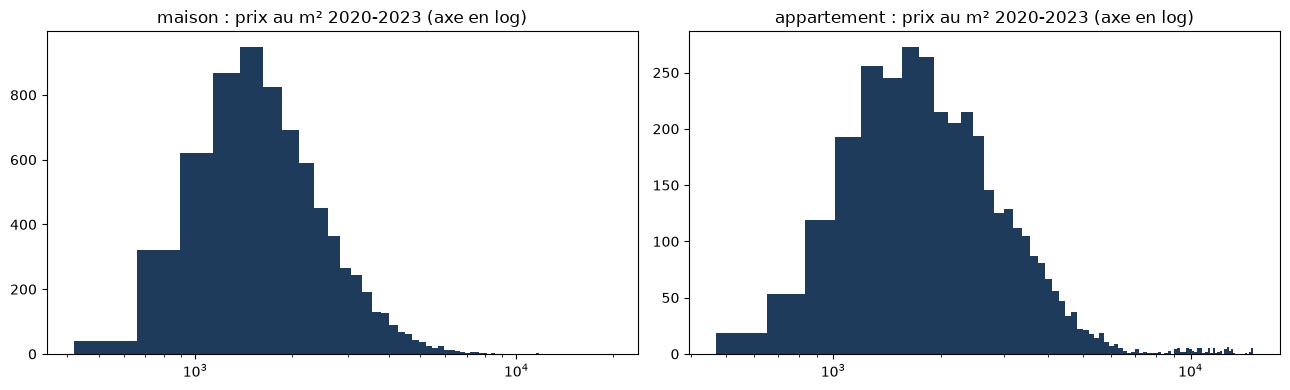

In [18]:
for type_bien in ["maison", "appartement"]:
    a = apprentissage[apprentissage["type_bien"] == type_bien]
    evolution = (a["prix"] / a["prix_n1"] - 1) * 100            # évolution N-1 -> N, en %
    print(type_bien, ": médiane =", a["prix"].median(), "€/m² | asymétrie =", round(a["prix"].skew(), 2),
          "| en log :", round(np.log(a["prix"]).skew(), 2),
          "| rho avec le prix N-1 =", round(stats.spearmanr(a["prix"], a["prix_n1"])[0], 3))
    print("   évolution médiane N-1 -> N par année (%) :", evolution.groupby(a["annee"]).median().round(1).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, type_bien in zip(axes, ["maison", "appartement"]):
    prix = apprentissage.loc[apprentissage["type_bien"] == type_bien, "prix"]
    ax.hist(prix, bins=80, color="#1f3b5c")
    ax.set_xscale("log")
    ax.set_title(type_bien + " : prix au m² 2020-2023 (axe en log)")
plt.tight_layout()
plt.show()

**Résultat :**

| | Prix médian | Asymétrie | Asymétrie du log | ρ avec le prix N-1 | Évolution médiane 2020 / 2021 / 2022 / 2023 |
|---|---|---|---|---|---|
| Maisons | 1 842 €/m² | 3,25 | 0,33 | 0,988 | +4,7 / +7,7 / +9,1 / +0,8 % |
| Appartements | 2 200 €/m² | 3,11 | 0,47 | 0,985 | +5,1 / +7,5 / +8,2 / +2,9 % |

**Conclusion :**
- Le prix est très asymétrique (quelques territoires très chers), mais **presque symétrique en log** : la régression linéaire travaillera sur le log du prix.
- **Le prix N-1 donne déjà presque tout le niveau** (ρ = 0,99). Ce qui reste à prévoir, c'est l'évolution d'une année à l'autre.
- Toutes les années d'apprentissage sont en hausse, alors que les prix baissent en 2024 : c'est ce qui rend la prévision naïve si difficile à battre.

## 3. Choix des variables

### 3.1 Variables écartées d'office
- `annee` : sert au découpage ; 2024 et 2025 sont hors de la plage d'apprentissage ;
- `n_ventes` : nombre de ventes de l'année N, inconnu au moment de prévoir (il ne sert qu'au seuil de 20 ventes) ;
- `part_indicateurs_estimes`, `part_logements_taux_impute`, `part_menages_couverts` : elles décrivent la fiabilité des sources, pas le territoire.

In [20]:
HORS_MODELE = ["annee", "sous_bassin_de_vie", "type_bien", "n_ventes", "prix",
               "part_indicateurs_estimes", "part_logements_taux_impute", "part_menages_couverts"]
VARIABLES = [c for c in table.columns if c not in HORS_MODELE]
# Variables du territoire : identiques pour les maisons et les appartements
TERRITOIRE = [c for c in VARIABLES if c not in ["maison", "prix_n1", "nb_ventes_n1"]]
print(len(VARIABLES), "variables candidates, dont", len(TERRITOIRE), "du territoire")

32 variables candidates, dont 29 du territoire


**Résultat :** 32 variables candidates : 29 du territoire, plus `maison`, `prix_n1` et `nb_ventes_n1`.

### 3.2 Variables redondantes
Deux variables qui classent les territoires presque de la même façon apportent la même information. On compare les variables du territoire deux à deux (Spearman), sur une ligne par sous-bassin et par année, et on signale les couples à |ρ| ≥ 0,75.

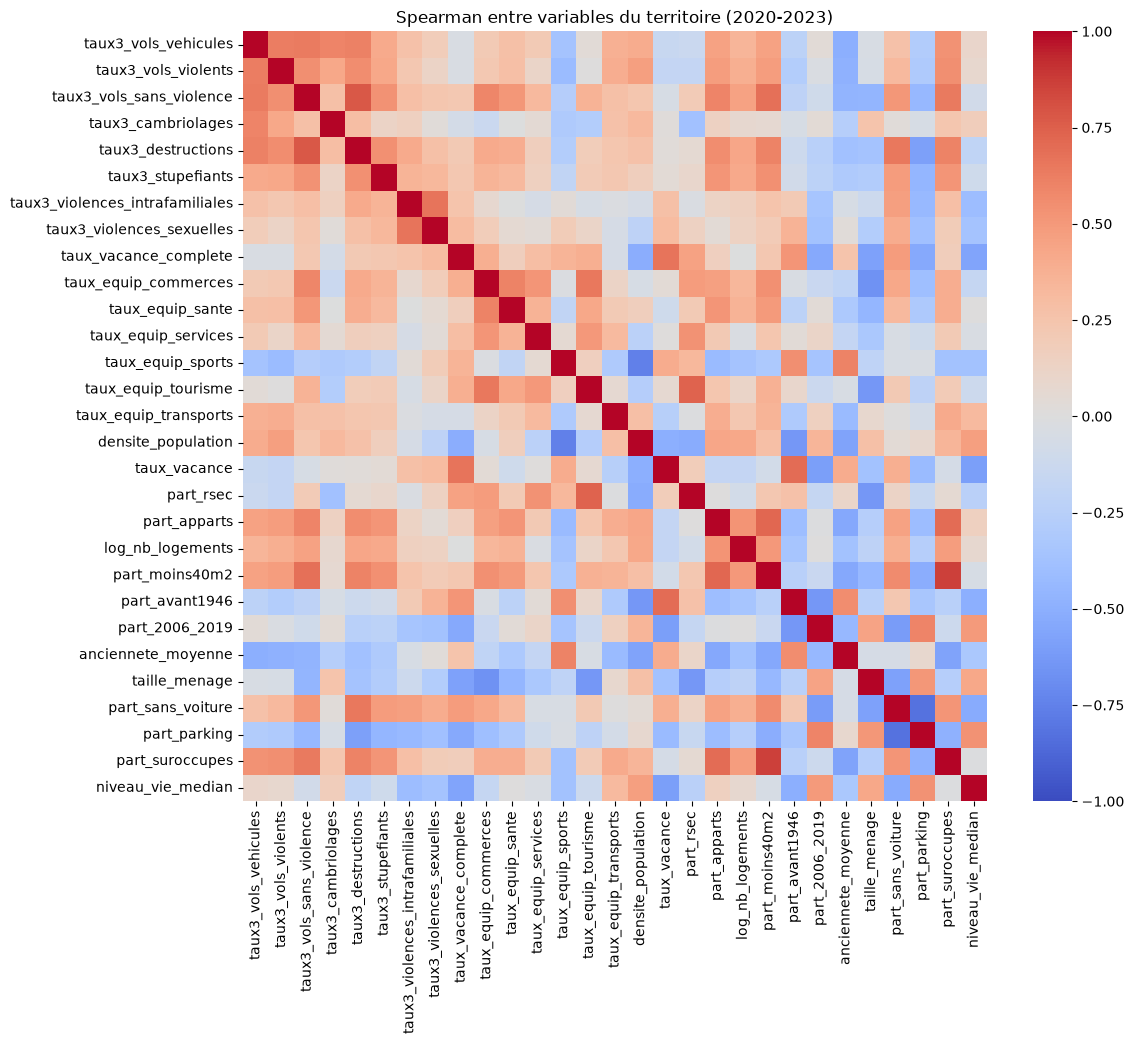

taux3_vols_sans_violence / taux3_destructions : rho = 0.78
taux_equip_sports / densite_population : rho = -0.75
part_moins40m2 / part_suroccupes : rho = 0.86
part_sans_voiture / part_parking : rho = -0.83


In [21]:
# Une ligne par sous-bassin x année : les variables du territoire ne dépendent pas du type de bien
territoires = apprentissage.drop_duplicates(["annee", "sous_bassin_de_vie"])
rho = territoires[TERRITOIRE].corr(method="spearman")

plt.figure(figsize=(12, 10))
sns.heatmap(rho, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Spearman entre variables du territoire (2020-2023)")
plt.show()

for i in range(len(TERRITOIRE)):
    for j in range(i + 1, len(TERRITOIRE)):
        if abs(rho.iloc[i, j]) >= 0.75:
            print(TERRITOIRE[i], "/", TERRITOIRE[j], ": rho =", round(rho.iloc[i, j], 2))

**Résultat :**

| Couple | ρ |
|---|---|
| petits logements / logements suroccupés | **0,86** |
| ménages sans voiture / ménages avec parking | **−0,83** |
| vols sans violence / destructions | 0,78 |
| équipements sportifs / densité | −0,75 |

**Conclusion :** deux couples dépassent 0,8, tous les deux dans le parc de logements. On retire **`part_suroccupes`** et **`part_parking`**. Les deux autres couples restent sous le seuil : on garde les quatre variables.

In [22]:
REDONDANTES = ["part_suroccupes", "part_parking"]
TERRITOIRE = [c for c in TERRITOIRE if c not in REDONDANTES]

### 3.3 Passage en log
Les variables très asymétriques (asymétrie > 1) donnent trop de poids à quelques territoires dans une régression linéaire ou une ACP. On les passe en log : log(x) en général, log(1 + x) si elles contiennent des zéros, log(x + 0,01) si leurs valeurs sont en plus très petites (médiane inférieure à 1).

In [23]:
asymetrie = territoires[TERRITOIRE].skew()
A_LOG = list(asymetrie[asymetrie > 1].index)
print(len(A_LOG), "variables à passer en log :", A_LOG)


def passer_en_log(donnees):
    """Passe en log les variables asymétriques (liste A_LOG)."""
    x = donnees.copy()
    for c in A_LOG:
        if (x[c] == 0).any():
            if x[c].median() < 1:
                x[c] = np.log(x[c] + 0.01)     # petites valeurs avec des zéros (vols violents)
            else:
                x[c] = np.log1p(x[c])          # zéros (équipements de tourisme, de transport)
        else:
            x[c] = np.log(x[c])
    return x


apres = passer_en_log(territoires[TERRITOIRE])[A_LOG].skew()
display(pd.DataFrame({"avant": asymetrie[A_LOG], "après": apres}).round(1))

20 variables à passer en log : ['taux3_vols_vehicules', 'taux3_vols_violents', 'taux3_vols_sans_violence', 'taux3_cambriolages', 'taux3_destructions', 'taux3_stupefiants', 'taux3_violences_intrafamiliales', 'taux3_violences_sexuelles', 'taux_equip_commerces', 'taux_equip_sante', 'taux_equip_services', 'taux_equip_sports', 'taux_equip_tourisme', 'taux_equip_transports', 'densite_population', 'part_rsec', 'part_apparts', 'part_moins40m2', 'part_sans_voiture', 'niveau_vie_median']


,avant,après
taux3_vols_vehicules,5.2,0.5
taux3_vols_violents,13.7,0.3
taux3_vols_sans_violence,19.3,1.9
taux3_cambriolages,1.2,-0.6
taux3_destructions,2.0,0.2
taux3_stupefiants,7.4,0.2
taux3_violences_intrafamiliales,1.1,-0.4
taux3_violences_sexuelles,1.9,-0.5
taux_equip_commerces,7.6,1.0
taux_equip_sante,2.7,0.2


**Résultat :** 20 variables passent en log : 8 de délinquance, 6 d'équipements, la densité, le niveau de vie et 4 parts du logement (résidences secondaires, appartements, petits logements, ménages sans voiture). L'asymétrie tombe sous 1 pour la plupart (vols violents 13,7 → 0,3 ; équipements de transport 16,8 → 0,2). Elle reste entre 1 et 2 pour les vols sans violence, la densité et le niveau de vie, tirés par les grandes villes.

**Conclusion :** cette transformation sert à la régression linéaire et à l'ACP. Elle est inutile pour les arbres, qui ne regardent que l'ordre des valeurs. Le volume de ventes N-1 (asymétrie 31), le prix et le prix N-1 seront passés en log dans la préparation des modèles, car ils dépendent du type de bien

## 4. Liens avec le prix
Corrélation de Spearman entre chaque variable et le prix, maisons et appartements séparés. On ajoute `part_logements_taux_impute` pour vérifier qu'une variable de contrôle n'est pas liée au prix.

In [24]:
lignes = []
for v in TERRITOIRE + ["nb_ventes_n1", "part_logements_taux_impute"]:
    ligne = {"variable": v}
    for type_bien in ["maison", "appartement"]:
        a = apprentissage[apprentissage["type_bien"] == type_bien].dropna(subset=[v])
        ligne[type_bien] = round(stats.spearmanr(a[v], a["prix"])[0], 2)
    lignes.append(ligne)
liens = pd.DataFrame(lignes).set_index("variable")
display(liens.reindex(liens.abs().max(axis=1).sort_values(ascending=False).index))

,maison,appartement
variable,,
part_avant1946,-0.76,-0.46
taux_vacance,-0.73,-0.61
anciennete_moyenne,-0.71,-0.46
niveau_vie_median,0.66,0.62
densite_population,0.64,0.40
part_2006_2019,0.62,0.35
taux_equip_sports,-0.61,-0.46
taux_equip_transports,0.50,0.47
part_logements_taux_impute,-0.50,-0.47


**Résultat (extrait) :**

| Variable | Maisons | Appartements |
|---|---|---|
| logements d'avant 1946 | **−0,76** | −0,46 |
| vacance (recensement) | **−0,73** | **−0,61** |
| ancienneté d'emménagement | **−0,71** | −0,46 |
| niveau de vie | **0,66** | **0,62** |
| densité | 0,64 | 0,40 |
| logements récents (2006-2019) | 0,62 | 0,35 |
| *logements au taux LOVAC complété (contrôle)* | *−0,50* | *−0,47* |
| … | | |
| cambriolages, stupéfiants, destructions | ≤ 0,18 | ≤ 0,11 |

**Conclusion :**
- Les prix sont surtout liés à **l'attractivité du parc** (ancien, vacant, habitants installés depuis longtemps : prix bas) et au **niveau de vie**. La délinquance compte peu.
- Les liens sont plus forts pour les maisons.
- **`part_logements_taux_impute` est liée au prix (−0,50)** : les taux LOVAC sont complétés dans les petites communes, donc cette variable de contrôle mesure en fait la ruralité. Ça confirme qu'il faut la laisser hors du modèle.

## 5. ACP des variables du territoire
**Pourquoi :** les 27 variables restantes sont liées entre elles. L'ACP cherche les quelques grandes différences entre territoires qu'elles décrivent.

**Choix :** une ligne par sous-bassin et par année d'apprentissage ; variables passées en log (3.3), puis standardisées (moyenne 0, écart-type 1) pour qu'aucune ne pèse plus à cause de son unité. Le prix n'entre pas dans l'ACP : on regarde ensuite son lien avec les axes.

### 5.1 Nombre d'axes

7236 lignes, 27 variables
Part de l'information par axe (%) : [31.4 19.7 11.7  5.3  4.6  3.1]
Part cumulée (%) : [31.4 51.1 62.8 68.1 72.7 75.8]


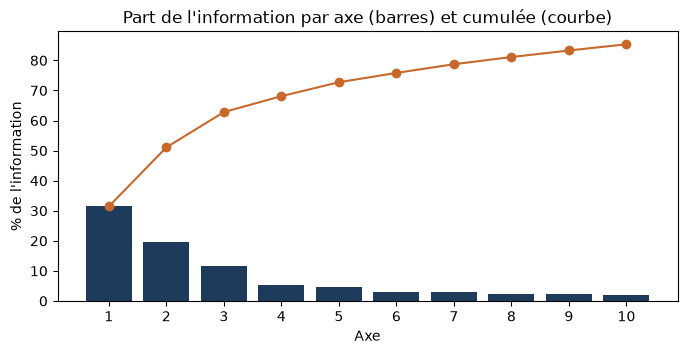

In [28]:
donnees_acp = territoires.dropna(subset=TERRITOIRE)          # sous-bassin sans LOVAC retiré
normalisation = StandardScaler().fit(passer_en_log(donnees_acp[TERRITOIRE]))   # moyennes et écarts-types de 2020-2023
Z = normalisation.transform(passer_en_log(donnees_acp[TERRITOIRE]))
acp = PCA().fit(Z)
part = acp.explained_variance_ratio_ * 100
print(len(donnees_acp), "lignes,", len(TERRITOIRE), "variables")
print("Part de l'information par axe (%) :", np.round(part[:6], 1))
print("Part cumulée (%) :", np.round(np.cumsum(part[:6]), 1))

plt.figure(figsize=(8, 3.5))
plt.bar(range(1, 11), part[:10], color="#1f3b5c")
plt.plot(range(1, 11), np.cumsum(part[:10]), color="#c8682b", marker="o")
plt.xlabel("Axe")
plt.ylabel("% de l'information")
plt.xticks(range(1, 11))
plt.title("Part de l'information par axe (barres) et cumulée (courbe)")
plt.show()

**Résultat :** les trois premiers axes portent 31,4 %, 19,7 % et 11,7 % de l'information, soit **63 % à eux trois**. Ensuite, chaque axe n'apporte plus que 3 à 5 %. On interprète ces trois axes.

### 5.2 Ce que mesurent les axes
La corrélation de chaque variable avec un axe montre ce qu'il mesure. Le cercle des corrélations le représente pour les deux premiers axes : chaque flèche est une variable, et deux flèches proches vont ensemble.

F1 | négatif : {'anciennete_moyenne': -0.65, 'taux_equip_sports': -0.54, 'taille_menage': -0.5, 'part_2006_2019': -0.16} | positif : {'taux3_destructions': 0.8, 'part_apparts': 0.81, 'part_moins40m2': 0.89, 'taux3_vols_sans_violence': 0.9}
F2 | négatif : {'taille_menage': -0.66, 'part_2006_2019': -0.66, 'densite_population': -0.6, 'niveau_vie_median': -0.58} | positif : {'part_rsec': 0.62, 'taux_vacance': 0.66, 'part_avant1946': 0.7, 'taux_vacance_complete': 0.76}
F3 | négatif : {'taux3_violences_intrafamiliales': -0.56, 'taux3_cambriolages': -0.49, 'taux_vacance': -0.45, 'part_sans_voiture': -0.4} | positif : {'part_2006_2019': 0.46, 'taux_equip_services': 0.57, 'part_rsec': 0.6, 'taux_equip_tourisme': 0.63}


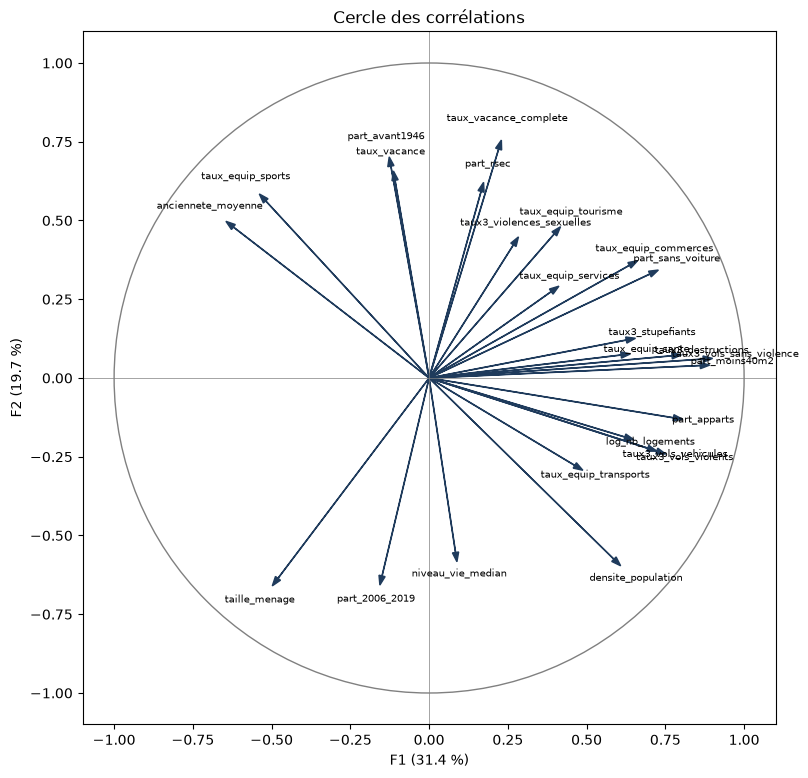

In [26]:
# Corrélation de chaque variable avec les 3 premiers axes
correlations = pd.DataFrame(acp.components_[:3].T * np.sqrt(acp.explained_variance_[:3]),
                            index=TERRITOIRE, columns=["F1", "F2", "F3"])
for f in ["F1", "F2", "F3"]:
    s = correlations[f].sort_values()
    print(f, "| négatif :", s.head(4).round(2).to_dict(), "| positif :", s.tail(4).round(2).to_dict())

# Cercle des corrélations (F1, F2) : seules les variables bien représentées sont tracées
fig, ax = plt.subplots(figsize=(9, 9))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for v in TERRITOIRE:
    x = correlations.loc[v, "F1"]
    y = correlations.loc[v, "F2"]
    if x ** 2 + y ** 2 > 0.25:
        ax.arrow(0, 0, x, y, head_width=0.02, color="#1f3b5c", length_includes_head=True)
        ax.text(x * 1.08, y * 1.08, v, fontsize=7, ha="center")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal")
ax.set_xlabel("F1 (" + str(round(part[0], 1)) + " %)")
ax.set_ylabel("F2 (" + str(round(part[1], 1)) + " %)")
ax.set_title("Cercle des corrélations")
plt.show()

**Résultat :**

| Axe | Il oppose… | … à | Lecture |
|---|---|---|---|
| **F1** (31 %) | habitants installés depuis longtemps, équipements sportifs par habitant, grands ménages | petits logements (0,89), appartements (0,81), vols sans violence (0,90), destructions (0,80) | **rural ↔ urbain dense** |
| **F2** (20 %) | logements récents, grands ménages, densité, niveau de vie élevé (−0,58 à −0,66) | vacance (0,66 et 0,76), logements d'avant 1946 (0,70), résidences secondaires (0,62) | **périurbain récent et aisé ↔ déprise** |
| **F3** (12 %) | violences intrafamiliales, cambriolages, vacance, ménages sans voiture | équipements touristiques (0,63), résidences secondaires (0,60), services (0,57) | **territoires populaires ↔ touristiques** |

Les territoires extrêmes confirment cette lecture : les arrondissements centraux de Paris, Lyon et Marseille en haut de F1 ; de petites villes thermales ou de montagne (Bourbonne-les-Bains, Luz-Saint-Sauveur) en haut de F2, les couronnes de Nantes et de Rennes en bas ; les stations de ski (Val-d'Isère, Morzine) en haut de F3.

### 5.3 Lien entre les axes et le prix

In [27]:
# Coordonnées de chaque sous-bassin x année sur les 3 axes, rapprochées du prix
axes_acp = pd.DataFrame(acp.transform(Z)[:, :3], columns=["F1", "F2", "F3"], index=donnees_acp.index)
axes_acp[["annee", "sous_bassin_de_vie"]] = donnees_acp[["annee", "sous_bassin_de_vie"]]
for type_bien in ["maison", "appartement"]:
    a = apprentissage[apprentissage["type_bien"] == type_bien].merge(axes_acp, on=["annee", "sous_bassin_de_vie"])
    print(type_bien, ": F1 =", round(stats.spearmanr(a["F1"], a["prix"])[0], 2),
          "| F2 =", round(stats.spearmanr(a["F2"], a["prix"])[0], 2),
          "| F3 =", round(stats.spearmanr(a["F3"], a["prix"])[0], 2))

maison : F1 = 0.42 | F2 = -0.67 | F3 = 0.41
appartement : F1 = 0.33 | F2 = -0.38 | F3 = 0.41


**Résultat (Spearman avec le prix) :**

| | F1 rural ↔ urbain | F2 périurbain aisé ↔ déprise | F3 populaire ↔ touristique |
|---|---|---|---|
| Maisons | 0,42 | **−0,67** | 0,41 |
| Appartements | 0,33 | −0,38 | 0,41 |

**Conclusion :** pour les maisons, c'est **F2** qui compte le plus : le prix dépend davantage de l'attractivité résidentielle (parc récent, ménages aisés, peu de vacance) que de l'opposition ville / campagne. Pour les appartements, les trois axes jouent à peu près autant. L'ACP sert à comprendre ces grandes dimensions ; dans les modèles, on garde les variables d'origine, qui contiennent plus d'information que les trois axes.



## 6. Les axes suffisent-ils à prévoir le prix ?

**Pourquoi :** l'ACP résume les 27 variables en 3 axes. On vérifie ce qu'on perd en ne donnant au modèle que ces 3 notes, et on regarde comment il s'en sert.

**Choix :**
- **Forêt aléatoire** : un ensemble d'arbres de décision. Elle capte les effets de seuil, et n'a besoin ni de log ni de standardisation pour les variables d'origine.
- **Une forêt par type de bien**, entraînée deux fois : sur les 3 axes, puis sur les 27 variables.
- **Sans le prix N-1** : il donnerait presque tout le niveau (section 2) et masquerait le reste. On mesure ici ce que le territoire explique seul.
- **Apprentissage 2020-2023, validation 2024.** Les notes 2024 sont calculées avec la standardisation et l'ACP apprises sur 2020-2023 : le modèle ne voit rien de 2024.
- Lignes du sous-bassin sans LOVAC retirées.

In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

validation = table[table["annee"] == ANNEE_VALIDATION]


def notes_acp(donnees):
    """Notes F1, F2, F3 des lignes, avec la standardisation et l'ACP apprises sur 2020-2023."""
    Z_lignes = normalisation.transform(passer_en_log(donnees[TERRITOIRE]))
    return pd.DataFrame(acp.transform(Z_lignes)[:, :3], columns=["F1", "F2", "F3"], index=donnees.index)


JEUX = {"3 axes de l'ACP": ["F1", "F2", "F3"], "27 variables": TERRITOIRE}
resultats = []
modeles = {}

for type_bien in ["maison", "appartement"]:
    # Lignes du type de bien, avec leurs notes sur les 3 axes ajoutées en colonnes
    app = apprentissage[apprentissage["type_bien"] == type_bien].dropna(subset=TERRITOIRE)
    val = validation[validation["type_bien"] == type_bien].dropna(subset=TERRITOIRE)
    app = pd.concat([app, notes_acp(app)], axis=1)
    val = pd.concat([val, notes_acp(val)], axis=1)

    for nom_jeu, colonnes in JEUX.items():
        foret = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1)
        foret.fit(app[colonnes], app["prix"])
        prevision = foret.predict(val[colonnes])
        modeles[(type_bien, nom_jeu)] = (foret, app[colonnes])
        resultats.append({"type de bien": type_bien, "variables": nom_jeu,
                          "R² validation 2024": r2_score(val["prix"], prevision),
                          "MAE 2024 (€/m²)": mean_absolute_error(val["prix"], prevision),
                          "MAE naïve (€/m²)": mean_absolute_error(val["prix"], val["prix_n1"])})

display(pd.DataFrame(resultats).round(2))

,type de bien,variables,R² validation 2024,MAE 2024 (€/m²),MAE naïve (€/m²)
0,maison,3 axes de l'ACP,0.77,329.08,129.19
1,maison,27 variables,0.89,186.66,129.19
2,appartement,3 axes de l'ACP,0.72,577.91,148.00
3,appartement,27 variables,0.92,309.07,148.00


**Résultat (validation 2024) :**

| Type de bien | Variables | R² | MAE | Rappel : naïve |
|---|---|---|---|---|
| Maisons | 3 axes de l'ACP | 0,77 | 329 €/m² | 129 €/m² |
| Maisons | 27 variables | **0,89** | **187 €/m²** | |
| Appartements | 3 axes de l'ACP | 0,72 | 578 €/m² | 148 €/m² |
| Appartements | 27 variables | **0,92** | **309 €/m²** | |

**Conclusion :**
- **Les 3 axes expliquent déjà les trois quarts des écarts de prix entre territoires** (R² de 0,77 et 0,72), avec seulement 3 nombres par sous-bassin.
- **Mais l'erreur est presque deux fois plus forte qu'avec les 27 variables.** Les 37 % d'information laissés de côté par l'ACP comptent pour le prix. On garde donc les variables d'origine dans les modèles.
- Sans le prix N-1, aucun des deux modèles n'approche la prévision naïve : le territoire dit où les prix sont hauts ou bas, pas comment ils évoluent d'une année à l'autre.

### 6.1 Comment le modèle se sert des axes (SHAP)
Pour chaque sous-bassin, SHAP indique de combien chaque axe fait monter ou baisser le prix prévu, en €/m², par rapport au prix moyen.

/Users/theophylechevet/Documents/LIORA/Projet immo/projet_compagnon/Immo_theo.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.
Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


maison : {'F1': 33.0, 'F2': 43.0, 'F3': 24.0}
appartement : {'F1': 38.0, 'F2': 28.0, 'F3': 34.0}


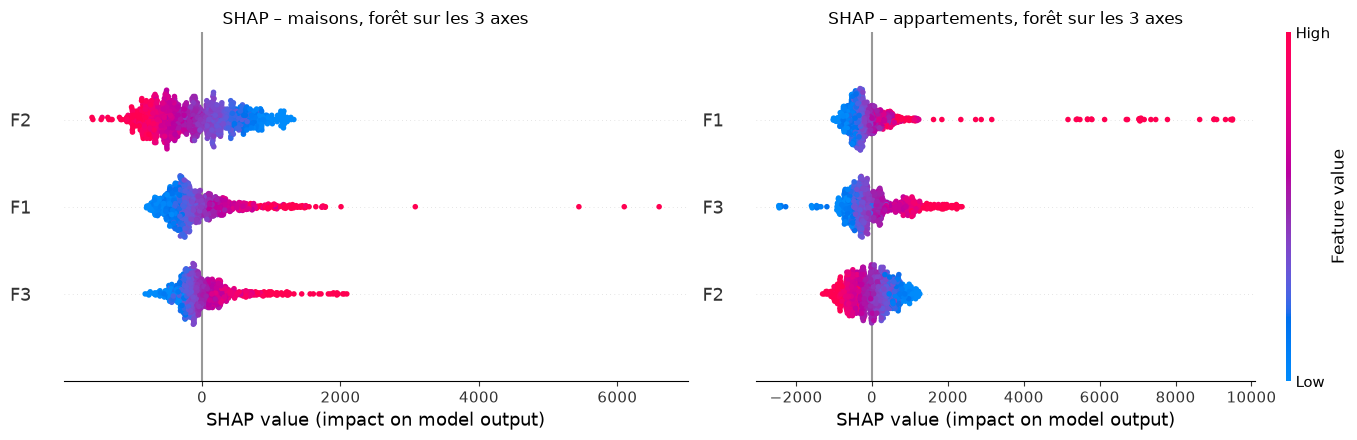

In [31]:
import shap

plt.figure(figsize=(14, 4.5))
for i, type_bien in enumerate(["maison", "appartement"], start=1):
    foret, X = modeles[(type_bien, "3 axes de l'ACP")]
    echantillon = X.sample(1000, random_state=42)          # 1 000 lignes suffisent pour le graphique
    reference = X.sample(200, random_state=1)              # lignes de référence pour le prix moyen
    valeurs = shap.TreeExplainer(foret, reference).shap_values(echantillon)

    # Part de chaque axe dans l'importance totale (moyenne des valeurs SHAP en valeur absolue)
    importance = pd.Series(np.abs(valeurs).mean(axis=0), index=X.columns)
    print(type_bien, ":", (importance / importance.sum() * 100).round(0).to_dict())

    plt.subplot(1, 2, i)
    shap.summary_plot(valeurs, echantillon, show=False, plot_size=None, color_bar=(i == 2))
    plt.title("SHAP – " + type_bien + "s, forêt sur les 3 axes")

plt.tight_layout()
plt.show()

**Lecture :** chaque point est un sous-bassin × année. Sa position donne de combien l'axe fait monter (à droite) ou baisser (à gauche) le prix prévu ; sa couleur donne la note sur l'axe (rouge = élevée, bleu = basse).

**Résultat :**

| | F1 rural ↔ urbain dense | F2 attire ↔ se vide | F3 populaire ↔ touristique |
|---|---|---|---|
| Part de l'importance – maisons | 34 % | **43 %** | 24 % |
| Part de l'importance – appartements | **37 %** | 28 % | 35 % |
| Sens de l'effet | note élevée → prix plus haut | note élevée → prix plus bas | note élevée → prix plus haut |

**Conclusion :**
- **Pour les maisons, F2 est l'axe le plus utilisé** : un territoire qui se vide fait baisser le prix prévu (jusqu'à −1 500 €/m²), un territoire qui attire le fait monter (jusqu'à +1 300 €/m²). Le modèle confirme le lien observé en 5.3 (ρ = −0,67).
- **Pour les appartements, F1 et F3 passent devant** : le prix suit la centralité urbaine et l'attrait touristique.
- **F1 agit surtout par ses valeurs extrêmes** : pour la plupart des territoires, il change peu le prix ; pour les centres de Paris, Lyon et Marseille, il ajoute jusqu'à +6 700 €/m² (maisons) et +9 500 €/m² (appartements). C'est un effet de seuil, qu'un arbre capte et qu'une régression linéaire capterait mal.

# Conclusions

| Constat | Décision pour la modélisation |
|---|---|
| Table complète sur 2020-2025, sauf un sous-bassin sans LOVAC (11 lignes) | Retirer ces lignes pour la régression linéaire |
| Prix très asymétrique, symétrique en log | Régression linéaire sur le log du prix |
| Le prix N-1 donne presque tout le niveau (ρ = 0,99) ; années d'apprentissage toutes en hausse, 2024 en baisse | La naïve reste la référence ; l'enjeu est l'évolution d'une année à l'autre |
| `annee`, `n_ventes` et les 3 variables de contrôle ne décrivent pas le territoire (et la part de logements imputés mesure la ruralité) | Hors modèle |
| Deux couples redondants (0,86 et −0,83) | Retirer `part_suroccupes` et `part_parking` : 27 variables du territoire |
| 20 variables du territoire très asymétriques, plus le volume de ventes N-1 | Log pour la régression linéaire, rien pour les arbres |
| Prix surtout liés au parc de logements, au niveau de vie et à la densité ; peu à la délinquance | Variables à tester en priorité |
| 3 dimensions résument 63 % des variables ; F2 (attractivité résidentielle) est la plus liée au prix des maisons (−0,67) | L'ACP sert à l'interprétation. Dans les modèles, on garde les variables d'origine : les 3 axes perdent 37 % de l'information et l'ACP les construit sans tenir compte du prix |
| Une forêt sur les 3 axes explique 72 à 77 % des écarts de prix, mais se trompe presque deux fois plus qu'avec les 27 variables (329 contre 187 €/m² pour les maisons) ; SHAP : F2 compte le plus pour les maisons, F1 et F3 pour les appartements | Les variables d'origine restent dans les modèles ; les axes servent à expliquer les résultats |